In [517]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


- drop all the orders that are not deliverd
- drop all the products that have no dimensions

In [518]:
customers = pd.read_csv('olist_customers_dataset.csv') 
items = pd.read_csv(
    'olist_order_items_dataset.csv',
    parse_dates=['shipping_limit_date']
)
orders    = pd.read_csv(
    'olist_orders_dataset.csv',
    parse_dates=['order_purchase_timestamp', 'order_approved_at', "order_delivered_carrier_date", "order_delivered_customer_date", "order_estimated_delivery_date" ]) 
products  = pd.read_csv('olist_products_dataset.csv')
sellers   = pd.read_csv('olist_sellers_dataset.csv')
geo       = pd.read_csv('olist_geolocation_dataset.csv')

In [519]:
items.info()

<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   order_id             112650 non-null  str           
 1   order_item_id        112650 non-null  int64         
 2   product_id           112650 non-null  str           
 3   seller_id            112650 non-null  str           
 4   shipping_limit_date  112650 non-null  datetime64[us]
 5   price                112650 non-null  float64       
 6   freight_value        112650 non-null  float64       
dtypes: datetime64[us](1), float64(2), int64(1), str(3)
memory usage: 16.3 MB


In [520]:
products.info()

<class 'pandas.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  str    
 1   product_category_name       32341 non-null  str    
 2   product_name_lenght         32341 non-null  float64
 3   product_description_lenght  32341 non-null  float64
 4   product_photos_qty          32341 non-null  float64
 5   product_weight_g            32949 non-null  float64
 6   product_length_cm           32949 non-null  float64
 7   product_height_cm           32949 non-null  float64
 8   product_width_cm            32949 non-null  float64
dtypes: float64(7), str(2)
memory usage: 3.7 MB


In [521]:
items_product = items.merge(products, on="product_id", how="left")

In [522]:
items_product.info()

<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 15 columns):
 #   Column                      Non-Null Count   Dtype         
---  ------                      --------------   -----         
 0   order_id                    112650 non-null  str           
 1   order_item_id               112650 non-null  int64         
 2   product_id                  112650 non-null  str           
 3   seller_id                   112650 non-null  str           
 4   shipping_limit_date         112650 non-null  datetime64[us]
 5   price                       112650 non-null  float64       
 6   freight_value               112650 non-null  float64       
 7   product_category_name       111047 non-null  str           
 8   product_name_lenght         111047 non-null  float64       
 9   product_description_lenght  111047 non-null  float64       
 10  product_photos_qty          111047 non-null  float64       
 11  product_weight_g            112632 non-null  float

In [523]:
items_product.loc[
    items_product["product_category_name"].isna()
].groupby("product_id").size().sort_values(ascending=False)
# items that dont have categories

product_id
5a848e4ab52fd5445cdc07aab1c40e48    197
b1d207586fca400a2370d50a9ba1da98     48
76d1a1a9d21ab677a61c3ae34b1b352f     32
3b60d513e90300a4e9833e5cda1f1d61     29
ad88641611c35ebd59ecda07a9f17099     29
                                   ... 
60d1e2123927bc621354b0ab11cc8fd5      1
5fb61f482620cb672f5e586bb132eae9      1
fe34503c6bccf918db601aaafd4a975a      1
fbd2a9aa1f115244e2ce115ad8eacfca      1
fb09c649a144a9dfd4546612891e1f11      1
Length: 610, dtype: int64

In [524]:
items_product = items_product[~(items_product["product_weight_g"].isna())]

In [525]:
items_product["product_category_name"] = items_product["product_category_name"].fillna("none")

In [526]:
items_product.drop(columns=["product_name_lenght","product_description_lenght","product_photos_qty"], inplace=True)

In [527]:
geo_mean = (geo
       .groupby("geolocation_zip_code_prefix")[["geolocation_lat", "geolocation_lng"]]
       .mean()
       .reset_index())

In [528]:
customers_geo = (
    customers.merge(
        geo_mean,
        left_on="customer_zip_code_prefix",
        right_on="geolocation_zip_code_prefix",
        how="left"
    )
    .rename(columns={
        "geolocation_lat": "customer_lat",
        "geolocation_lng": "customer_lng"
    })
    .drop(columns="geolocation_zip_code_prefix")
)

In [529]:
seller_geo = (
    sellers.merge(
        geo_mean,
        left_on="seller_zip_code_prefix",
        right_on="geolocation_zip_code_prefix",
        how="left"
    )
    .rename(columns={
        "geolocation_lat": "seller_lat",
        "geolocation_lng": "seller_lng"
    })
    .drop(columns="geolocation_zip_code_prefix")
)

In [530]:
items_product_seller = items_product.merge(seller_geo, on="seller_id", how="left")

In [531]:
items_product_seller.info()

<class 'pandas.DataFrame'>
RangeIndex: 112632 entries, 0 to 112631
Data columns (total 17 columns):
 #   Column                  Non-Null Count   Dtype         
---  ------                  --------------   -----         
 0   order_id                112632 non-null  str           
 1   order_item_id           112632 non-null  int64         
 2   product_id              112632 non-null  str           
 3   seller_id               112632 non-null  str           
 4   shipping_limit_date     112632 non-null  datetime64[us]
 5   price                   112632 non-null  float64       
 6   freight_value           112632 non-null  float64       
 7   product_category_name   112632 non-null  str           
 8   product_weight_g        112632 non-null  float64       
 9   product_length_cm       112632 non-null  float64       
 10  product_height_cm       112632 non-null  float64       
 11  product_width_cm        112632 non-null  float64       
 12  seller_zip_code_prefix  112632 non-null  

In [532]:
items_product_seller_customer = items_product_seller.merge(orders[["order_id", "customer_id"]], on="order_id", how="left")
items_product_seller_customer = items_product_seller_customer.merge(
    customers_geo, on="customer_id", how="left"
)

In [533]:
items_product_seller_customer

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,product_weight_g,product_length_cm,...,seller_state,seller_lat,seller_lng,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,customer_lat,customer_lng
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,cool_stuff,650.0,28.0,...,SP,-22.496953,-44.127492,3ce436f183e68e07877b285a838db11a,871766c5855e863f6eccc05f988b23cb,28013,campos dos goytacazes,RJ,-21.762775,-41.309633
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,pet_shop,30000.0,50.0,...,SP,-23.565096,-46.518565,f6dd3ec061db4e3987629fe6b26e5cce,eb28e67c4c0b83846050ddfb8a35d051,15775,santa fe do sul,SP,-20.220527,-50.903424
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,moveis_decoracao,3050.0,33.0,...,MG,-22.262584,-46.171124,6489ae5e4333f3693df5ad4372dab6d3,3818d81c6709e39d06b2738a8d3a2474,35661,para de minas,MG,-19.870305,-44.593326
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,perfumaria,200.0,16.0,...,SP,-20.553624,-47.387359,d4eb9395c8c0431ee92fce09860c5a06,af861d436cfc08b2c2ddefd0ba074622,12952,atibaia,SP,-23.089925,-46.611654
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,ferramentas_jardim,3750.0,35.0,...,PR,-22.929384,-53.135873,58dbd0b2d70206bf40e62cd34e84d795,64b576fb70d441e8f1b2d7d446e483c5,13226,varzea paulista,SP,-23.243402,-46.827614
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
112627,fffc94f6ce00a00581880bf54a75a037,1,4aa6014eceb682077f9dc4bffebc05b0,b8bc237ba3788b23da09c0f1f3a3288c,2018-05-02 04:11:01,299.99,43.41,utilidades_domesticas,10150.0,89.0,...,SC,-26.912574,-48.673980,b51593916b4b8e0d6f66f2ae24f2673d,0c9aeda10a71f369396d0c04dce13a64,65077,sao luis,MA,-2.497993,-44.297761
112628,fffcd46ef2263f404302a634eb57f7eb,1,32e07fd915822b0765e448c4dd74c828,f3c38ab652836d21de61fb8314b69182,2018-07-20 04:31:48,350.00,36.53,informatica_acessorios,8950.0,45.0,...,SP,-23.535864,-46.642819,84c5d4fbaf120aae381fad077416eaa0,0da9fe112eae0c74d3ba1fe16de0988b,81690,curitiba,PR,-25.566904,-49.309115
112629,fffce4705a9662cd70adb13d4a31832d,1,72a30483855e2eafc67aee5dc2560482,c3cfdc648177fdbbbb35635a37472c53,2017-10-30 17:14:25,99.90,16.95,esporte_lazer,967.0,21.0,...,PR,-25.469955,-49.289821,29309aa813182aaddc9b259e31b870e6,cd79b407828f02fdbba457111c38e4c4,4039,sao paulo,SP,-23.597794,-46.643923
112630,fffe18544ffabc95dfada21779c9644f,1,9c422a519119dcad7575db5af1ba540e,2b3e4a2a3ea8e01938cabda2a3e5cc79,2017-08-21 00:04:32,55.99,8.72,informatica_acessorios,100.0,20.0,...,SP,-23.635530,-46.694031,b5e6afd5a41800fdf401e0272ca74655,eb803377c9315b564bdedad672039306,13289,vinhedo,SP,-23.040252,-46.979782


In [534]:
feat = items_product_seller.groupby("order_id").agg(
    n_items=("order_item_id", "count"),
    n_distinct_products=("product_id", "nunique"),
    total_weight_g=("product_weight_g", "sum"),
    n_sellers=("seller_id", "nunique"),
    n_distinct_categories=("product_category_name", "nunique"),
).reset_index()

In [535]:
feat.info()

<class 'pandas.DataFrame'>
RangeIndex: 98650 entries, 0 to 98649
Data columns (total 6 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   order_id               98650 non-null  str    
 1   n_items                98650 non-null  int64  
 2   n_distinct_products    98650 non-null  int64  
 3   total_weight_g         98650 non-null  float64
 4   n_sellers              98650 non-null  int64  
 5   n_distinct_categories  98650 non-null  int64  
dtypes: float64(1), int64(4), str(1)
memory usage: 7.5 MB


In [536]:
feat.describe()

,n_items,n_distinct_products,total_weight_g,n_sellers,n_distinct_categories
count,98650.000000,98650.000000,98650.000000,98650.000000,98650.000000
mean,1.141733,1.038104,2390.415307,1.013624,1.008150
std,0.538480,0.226474,4773.529840,0.122307,0.091916
min,1.000000,1.000000,0.000000,1.000000,1.000000
25%,1.000000,1.000000,300.000000,1.000000,1.000000
50%,1.000000,1.000000,750.000000,1.000000,1.000000
75%,1.000000,1.000000,2068.750000,1.000000,1.000000
max,21.000000,8.000000,184400.000000,5.000000,3.000000


In [537]:
feat.head()

,order_id,n_items,n_distinct_products,total_weight_g,n_sellers,n_distinct_categories
0,00010242fe8c5a6d1ba2dd792cb16214,1,1,650.0,1,1
1,00018f77f2f0320c557190d7a144bdd3,1,1,30000.0,1,1
2,000229ec398224ef6ca0657da4fc703e,1,1,3050.0,1,1
3,00024acbcdf0a6daa1e931b038114c75,1,1,200.0,1,1
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,1,3750.0,1,1


In [538]:
geo["geolocation_zip_code_prefix"].duplicated().sum()

np.int64(981148)

In [539]:
geo.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000163 entries, 0 to 1000162
Data columns (total 5 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   geolocation_zip_code_prefix  1000163 non-null  int64  
 1   geolocation_lat              1000163 non-null  float64
 2   geolocation_lng              1000163 non-null  float64
 3   geolocation_city             1000163 non-null  str    
 4   geolocation_state            1000163 non-null  str    
dtypes: float64(2), int64(1), str(2)
memory usage: 50.1 MB


In [540]:
geo_mean.info()

<class 'pandas.DataFrame'>
RangeIndex: 19015 entries, 0 to 19014
Data columns (total 3 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   geolocation_zip_code_prefix  19015 non-null  int64  
 1   geolocation_lat              19015 non-null  float64
 2   geolocation_lng              19015 non-null  float64
dtypes: float64(2), int64(1)
memory usage: 445.8 KB


In [541]:
customers_geo.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 7 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   customer_id               99441 non-null  str    
 1   customer_unique_id        99441 non-null  str    
 2   customer_zip_code_prefix  99441 non-null  int64  
 3   customer_city             99441 non-null  str    
 4   customer_state            99441 non-null  str    
 5   customer_lat              99163 non-null  float64
 6   customer_lng              99163 non-null  float64
dtypes: float64(2), int64(1), str(4)
memory usage: 12.6 MB


In [542]:
customers_geo[customers_geo["customer_lat"].isna()]

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,customer_lat,customer_lng
354,ecb1725b26e8b8c458181455dfa434ea,b55a113bb84fc10eaf58c6d09ec69794,72300,brasilia,DF,NaN,NaN
382,bcf86029aeed4ed8bac0e16eb14c22f5,7cd7974c9f79f75b77f323878ef87f43,11547,cubatao,SP,NaN,NaN
877,f4302056f0c58570522590f8181de2c7,67b05b597a66b5c449025000b9430abb,64605,picos,PI,NaN,NaN
1218,03bbe0ce5c28e05f22917607db798818,8f3dca4306d5a89e4ae2c65c110603a2,72465,brasilia,DF,NaN,NaN
1272,ad4950aded55c2ea376be59506456d68,aa2b96dd03307ea6dc4b763c0b5f0b39,7729,caieiras,SP,NaN,NaN
...,...,...,...,...,...,...,...
97467,cf818420383856a129134f5f8343f7b8,795c495a65f983b242fb01bd507977c5,72338,brasilia,DF,NaN,NaN
97780,67f3e907dce402e696b15f9308ff22ed,6f232f2f5c7f33b7bd9d794d2afacadd,68629,paragominas,PA,NaN,NaN
98140,f792e419335df11d82c32efcfb09c51b,c04c085b8e7573ba87b9ae1968d0985e,28530,sao sebastiao do paraiba,RJ,NaN,NaN
98878,78a11bb1fa72f556996b9a5b9bcd0629,e7536f62a200b415edd9491ac12a17fa,55863,siriji,PE,NaN,NaN


In [543]:
seller_geo.info()

<class 'pandas.DataFrame'>
RangeIndex: 3095 entries, 0 to 3094
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   seller_id               3095 non-null   str    
 1   seller_zip_code_prefix  3095 non-null   int64  
 2   seller_city             3095 non-null   str    
 3   seller_state            3095 non-null   str    
 4   seller_lat              3088 non-null   float64
 5   seller_lng              3088 non-null   float64
dtypes: float64(2), int64(1), str(3)
memory usage: 278.7 KB


In [544]:
df = orders.merge(feat, on="order_id", how="left")

In [545]:
df

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,n_items,n_distinct_products,total_weight_g,n_sellers,n_distinct_categories
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,1.0,1.0,500.0,1.0,1.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,1.0,1.0,400.0,1.0,1.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,1.0,1.0,420.0,1.0,1.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,1.0,1.0,450.0,1.0,1.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,1.0,1.0,250.0,1.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
99436,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,delivered,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28,1.0,1.0,1175.0,1.0,1.0
99437,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02,1.0,1.0,4950.0,1.0,1.0
99438,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27,1.0,1.0,13300.0,1.0,1.0
99439,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15,2.0,1.0,13100.0,1.0,1.0


In [546]:
items_t = (items
         .merge(products, on="product_id", how="left")
         .merge(seller_geo, on="seller_id", how="left")
         .merge(orders[["order_id", "customer_id"]], on="order_id", how="left")
         .merge(customers_geo, on="customer_id", how="left"))

In [547]:
items_t.info()

<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 27 columns):
 #   Column                      Non-Null Count   Dtype         
---  ------                      --------------   -----         
 0   order_id                    112650 non-null  str           
 1   order_item_id               112650 non-null  int64         
 2   product_id                  112650 non-null  str           
 3   seller_id                   112650 non-null  str           
 4   shipping_limit_date         112650 non-null  datetime64[us]
 5   price                       112650 non-null  float64       
 6   freight_value               112650 non-null  float64       
 7   product_category_name       111047 non-null  str           
 8   product_name_lenght         111047 non-null  float64       
 9   product_description_lenght  111047 non-null  float64       
 10  product_photos_qty          111047 non-null  float64       
 11  product_weight_g            112632 non-null  float

In [548]:
def haversine_km(lat1, lng1, lat2, lng2):
    lat1, lng1, lat2, lng2 = map(np.radians, [lat1, lng1, lat2, lng2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lng2 - lng1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

In [549]:
items_product_seller_customer["distance_km"] = haversine_km(items_product_seller_customer.seller_lat, items_product_seller_customer.seller_lng,
                                    items_product_seller_customer.customer_lat, items_product_seller_customer.customer_lng)
items_product_seller_customer["longest_side_cm"] = items_product_seller_customer[["product_length_cm", "product_height_cm", "product_width_cm"]].max(axis=1)
items_product_seller_customer["same_state"] = (items_product_seller_customer.seller_state == items_product_seller_customer.customer_state).astype(int)

extra = items_product_seller_customer.groupby("order_id").agg(
    max_longest_side_cm=("longest_side_cm", "max"),
    max_distance_km=("distance_km", "max"),
    mean_distance_km=("distance_km", "mean"),
    all_same_state=("same_state", "min"),
    distance_missing=("distance_km", lambda s: int(s.isna().any())),
).reset_index()

In [550]:
extra

,order_id,max_longest_side_cm,max_distance_km,mean_distance_km,all_same_state,distance_missing
0,00010242fe8c5a6d1ba2dd792cb16214,28.0,301.504681,301.504681,0,0
1,00018f77f2f0320c557190d7a144bdd3,50.0,585.563937,585.563937,1,0
2,000229ec398224ef6ca0657da4fc703e,33.0,312.343511,312.343511,1,0
3,00024acbcdf0a6daa1e931b038114c75,16.0,293.168420,293.168420,1,0
4,00042b26cf59d7ce69dfabb4e55b4fd9,40.0,646.163463,646.163463,0,0
...,...,...,...,...,...,...
98645,fffc94f6ce00a00581880bf54a75a037,89.0,2754.537709,2754.537709,0,0
98646,fffcd46ef2263f404302a634eb57f7eb,45.0,351.729420,351.729420,0,0
98647,fffce4705a9662cd70adb13d4a31832d,24.0,339.056961,339.056961,0,0
98648,fffe18544ffabc95dfada21779c9644f,20.0,72.335998,72.335998,1,0


In [551]:
df = df.merge(extra, on="order_id", how="left")

In [552]:
df

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,n_items,n_distinct_products,total_weight_g,n_sellers,n_distinct_categories,max_longest_side_cm,max_distance_km,mean_distance_km,all_same_state,distance_missing
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,1.0,1.0,500.0,1.0,1.0,19.0,18.576110,18.576110,1.0,0.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,1.0,1.0,400.0,1.0,1.0,19.0,851.495069,851.495069,0.0,0.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,1.0,1.0,420.0,1.0,1.0,24.0,514.410666,514.410666,0.0,0.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,1.0,1.0,450.0,1.0,1.0,30.0,1822.226336,1822.226336,0.0,0.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,1.0,1.0,250.0,1.0,1.0,51.0,29.676625,29.676625,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99436,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,delivered,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28,1.0,1.0,1175.0,1.0,1.0,22.0,69.755064,69.755064,1.0,0.0
99437,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02,1.0,1.0,4950.0,1.0,1.0,40.0,474.120037,474.120037,1.0,0.0
99438,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27,1.0,1.0,13300.0,1.0,1.0,90.0,967.847297,967.847297,0.0,0.0
99439,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15,2.0,1.0,13100.0,1.0,1.0,20.0,370.404482,370.404482,0.0,0.0


In [553]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 18 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  str           
 1   customer_id                    99441 non-null  str           
 2   order_status                   99441 non-null  str           
 3   order_purchase_timestamp       99441 non-null  datetime64[us]
 4   order_approved_at              99281 non-null  datetime64[us]
 5   order_delivered_carrier_date   97658 non-null  datetime64[us]
 6   order_delivered_customer_date  96476 non-null  datetime64[us]
 7   order_estimated_delivery_date  99441 non-null  datetime64[us]
 8   n_items                        98650 non-null  float64       
 9   n_distinct_products            98650 non-null  float64       
 10  total_weight_g                 98650 non-null  float64       
 11  n_sellers                 

In [554]:
items_product["volume_cm3"] = (items_product.product_length_cm
                              * items_product.product_height_cm
                              * items_product.product_width_cm)

vol = items_product.groupby("order_id").agg(
    total_volume_cm3=("volume_cm3", "sum"),
    max_single_item_weight_g=("product_weight_g", "max"),
).reset_index()

df = df.merge(vol, on="order_id", how="left")

In [555]:
df = df[(df.order_status == "delivered")
        & df.order_delivered_customer_date.notna()
        & df.n_items.notna()]


df = df.dropna(subset=["max_distance_km", "mean_distance_km"])
df = df[(df.max_distance_km <= 4500) & (df.total_weight_g > 0)]

In [556]:
df = df.copy()

df["delivery_hours"] = (df.order_delivered_customer_date
                        - df.order_purchase_timestamp).dt.total_seconds() / 3600
df["order_hour"]  = df.order_purchase_timestamp.dt.hour
df["order_dow"]   = df.order_purchase_timestamp.dt.dayofweek
df["order_month"] = df.order_purchase_timestamp.dt.month

final_cols = [
    "order_id", "customer_id", "order_status",
    "order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
    "order_delivered_customer_date", "order_estimated_delivery_date",
    "total_volume_cm3", "max_single_item_weight_g",
    "n_items", "n_distinct_products", "total_weight_g", "n_sellers", "n_distinct_categories",
    "max_distance_km", "mean_distance_km", "all_same_state",
    "delivery_hours", "order_hour", "order_dow", "order_month",
]
df = df[final_cols].reset_index(drop=True)

In [557]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 95968 entries, 0 to 95967
Data columns (total 22 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       95968 non-null  str           
 1   customer_id                    95968 non-null  str           
 2   order_status                   95968 non-null  str           
 3   order_purchase_timestamp       95968 non-null  datetime64[us]
 4   order_approved_at              95954 non-null  datetime64[us]
 5   order_delivered_carrier_date   95967 non-null  datetime64[us]
 6   order_delivered_customer_date  95968 non-null  datetime64[us]
 7   order_estimated_delivery_date  95968 non-null  datetime64[us]
 8   total_volume_cm3               95968 non-null  float64       
 9   max_single_item_weight_g       95968 non-null  float64       
 10  n_items                        95968 non-null  float64       
 11  n_distinct_products       

In [558]:
df = df[~(df["order_delivered_customer_date"].isna())]
df = df[~(df["order_delivered_carrier_date"].isna())]
df = df[~(df["order_approved_at"].isna())]

In [559]:
X = df[["n_items", "n_distinct_products", "n_sellers", "n_distinct_categories","total_weight_g", "max_single_item_weight_g", "total_volume_cm3","max_distance_km", "mean_distance_km", "all_same_state","order_hour", "order_dow", "order_month"]]

y = df["delivery_hours"]

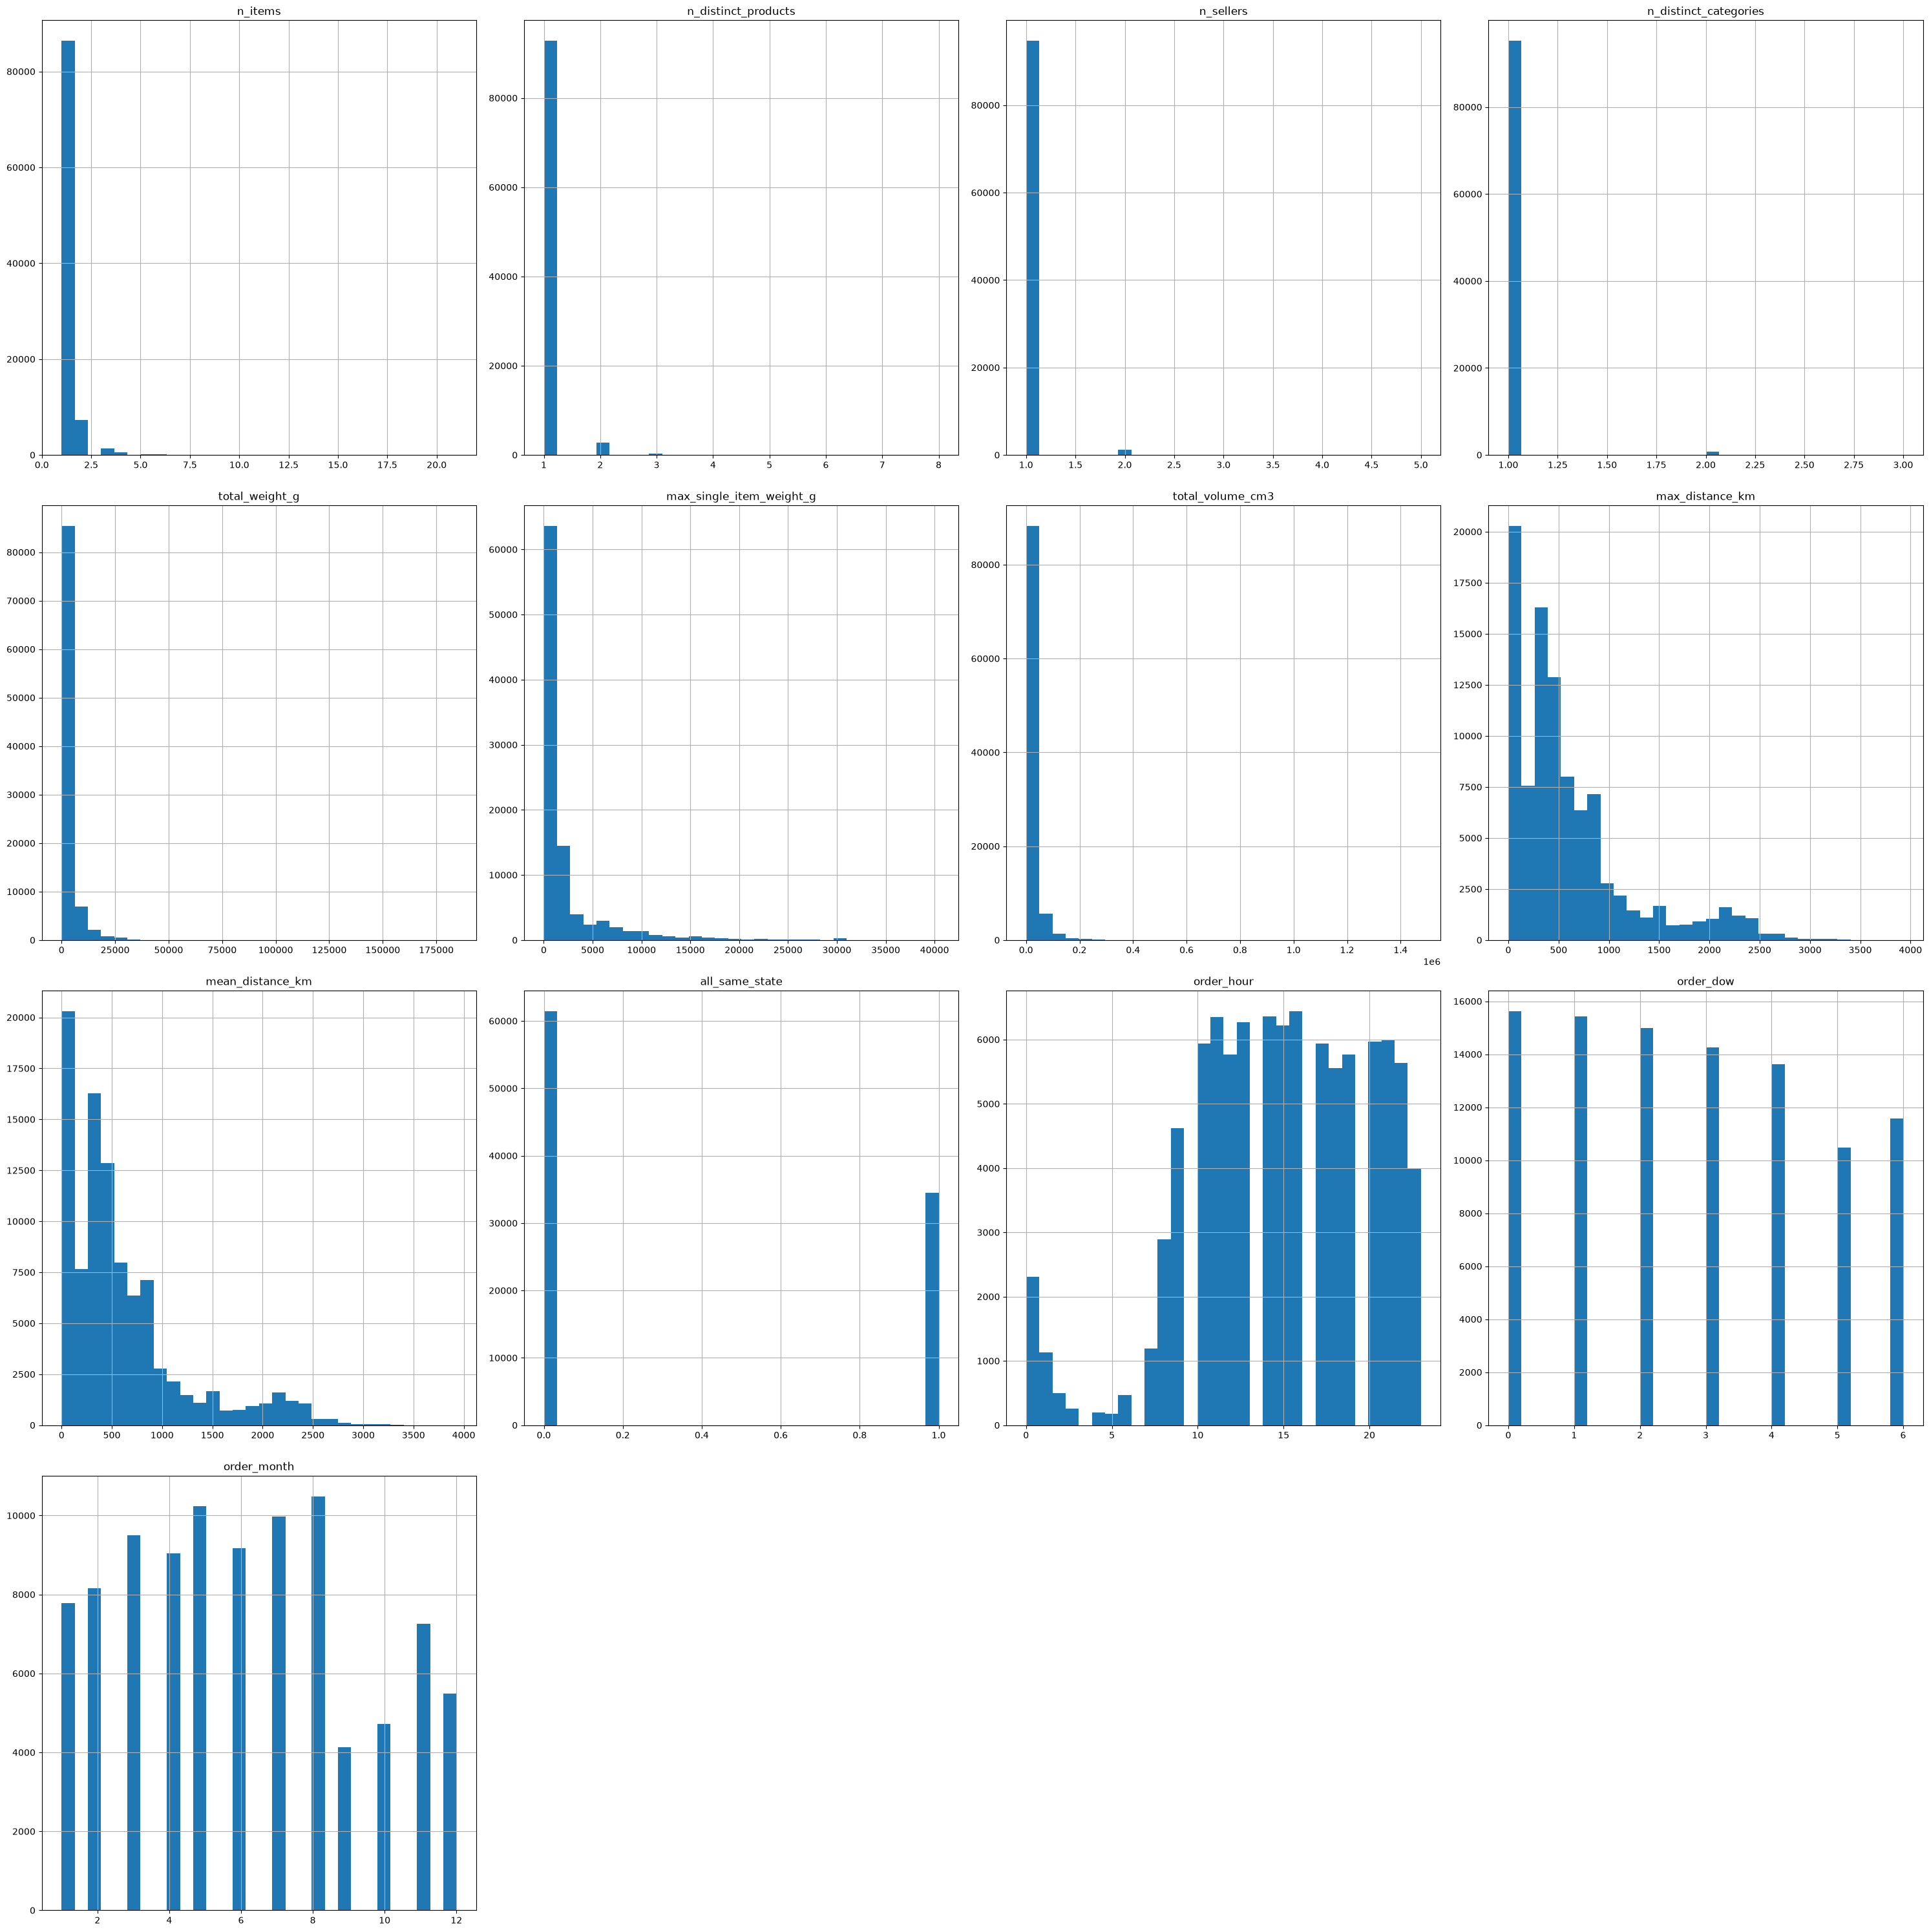

In [560]:
X.hist(figsize=(30, 30), bins=30)
plt.tight_layout()
plt.show()

<Axes: >

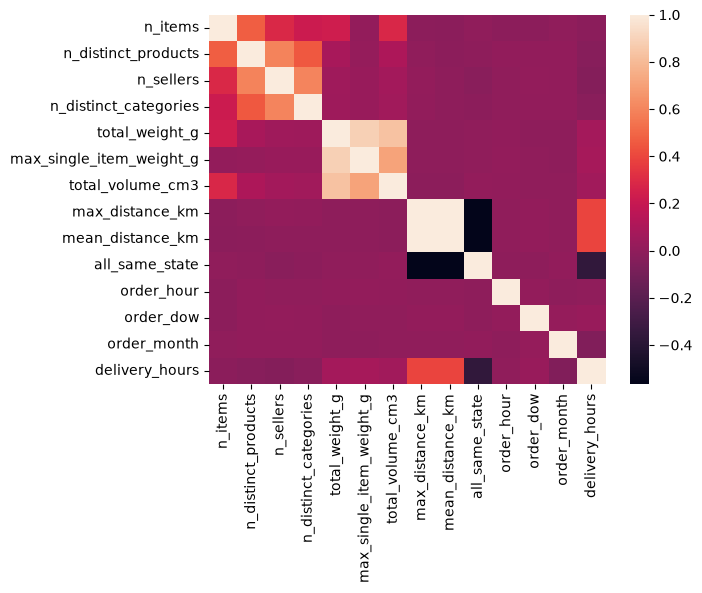

In [561]:
sns.heatmap(pd.concat([X, y], axis=1).corr())


In [562]:
pd.concat([X, y], axis=1).corr()["delivery_hours"].sort_values(ascending=False)

delivery_hours              1.000000
mean_distance_km            0.394201
max_distance_km             0.392990
max_single_item_weight_g    0.078816
total_weight_g              0.071455
total_volume_cm3            0.063002
order_dow                   0.029316
order_hour                  0.001547
n_items                    -0.018957
n_distinct_categories      -0.027327
n_distinct_products        -0.029741
n_sellers                  -0.040479
order_month                -0.055040
all_same_state             -0.361242
Name: delivery_hours, dtype: float64

In [563]:
y.describe()

count    95953.000000
mean       301.152740
std        229.061659
min         12.801944
25%        162.165000
50%        245.024444
75%        376.875556
max       5031.086667
Name: delivery_hours, dtype: float64

In [564]:
from sklearn.model_selection import train_test_split

X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.2, random_state=42)

In [565]:
print(X_train.shape, y_train.shape)
print(X_val.shape, y_val.shape)
print(X_test.shape, y_test.shape)

(61409, 13) (61409,)
(15353, 13) (15353,)
(19191, 13) (19191,)


In [566]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

dt_pipe = make_pipeline(StandardScaler(), DecisionTreeRegressor(max_depth=5, min_samples_leaf=50))
lr_pipe = make_pipeline(StandardScaler(), LinearRegression())
knn_pipe = make_pipeline(StandardScaler(), KNeighborsRegressor())
ran_pipe = make_pipeline(StandardScaler(), RandomForestRegressor())
hist_pipe = make_pipeline(StandardScaler(), HistGradientBoostingRegressor())

for i in [dt_pipe, lr_pipe, knn_pipe, ran_pipe, hist_pipe]:
    i.fit(X_train, y_train)

In [567]:
from sklearn.metrics import mean_absolute_error
for i in [dt_pipe, lr_pipe, knn_pipe, ran_pipe, hist_pipe]:
    y_pred = i.predict(X_val)
    print(mean_absolute_error(y_val, y_pred))

125.5986477230175
131.6526314927431
137.7803927571159
129.6809525756076
122.93540790150362


In [ ]:
# **hist_pipe** is the best model out of them, Approximately 5.11 days of average absolute prediction error.